In [1]:
# ---- Importing Media ---- #
from media import medium_helper

SiN = medium_helper.get_medium(
    "si3n4",
    (0.600, 1.200),
)

SiO2 = medium_helper.get_medium(
    "sio2",
    (0.600, 1.200)
)

Si = medium_helper.get_medium(
    "si",
    (0.600, 1.200)
)

Air = medium_helper.get_medium(
    "air",
    (0.600, 1.200)
)

2026-07-23 05:29:23,800 - media.medium_helper - INFO - [Medium] Loading si3n4 cached fit from Luke_Si3N4.json...
2026-07-23 05:29:23,801 - media.medium_helper - INFO - [Medium] Loading sio2 cached fit from Nyakuchena_fusedSilica.json...
2026-07-23 05:29:23,802 - media.medium_helper - INFO - [Medium] Loading si cached fit from Franta_Si_300K.json...
2026-07-23 05:29:23,804 - media.medium_helper - INFO - [Medium] Bypassing file system for air. Returning dispersionless vacuum medium (n=1.0)...


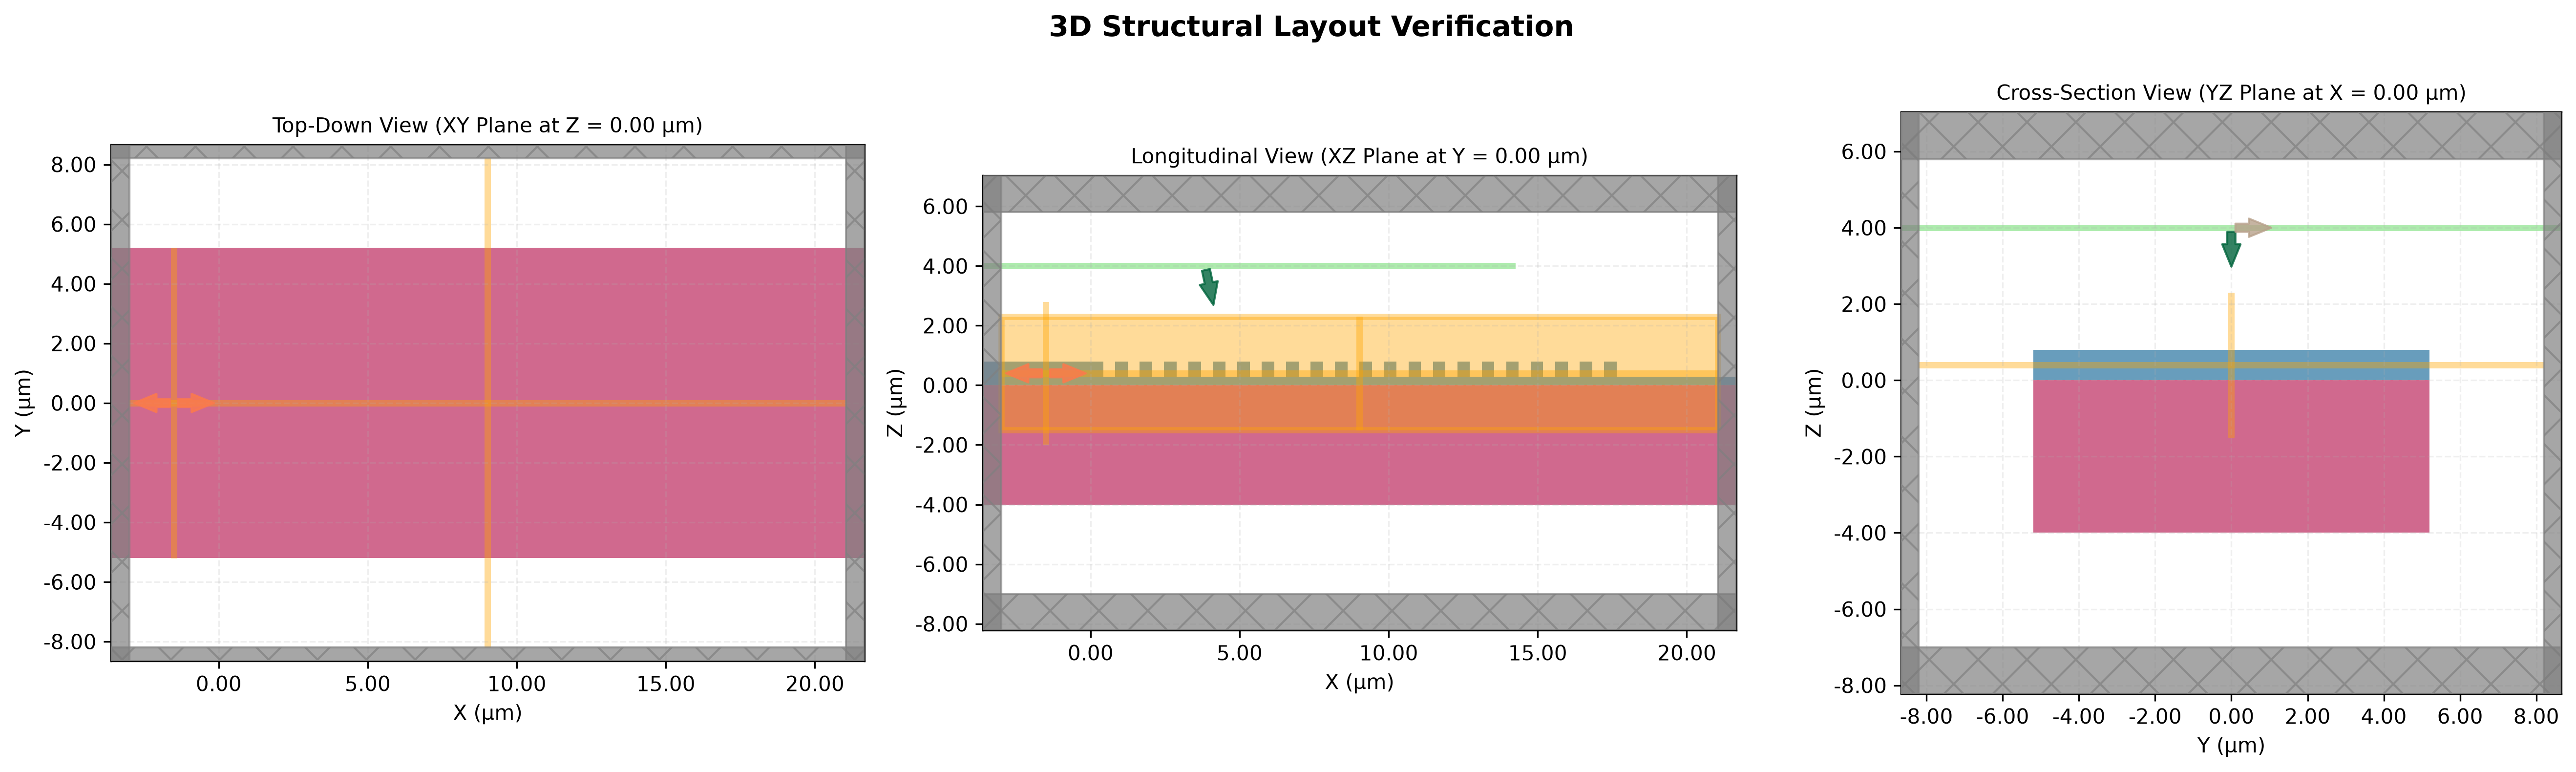

2026-07-23 05:29:25,544 - utilities.sim_plotter - INFO - [Visualizer] 3D orthogonal layout sheet saved to: example_results/grating_coupler/example_3d.png


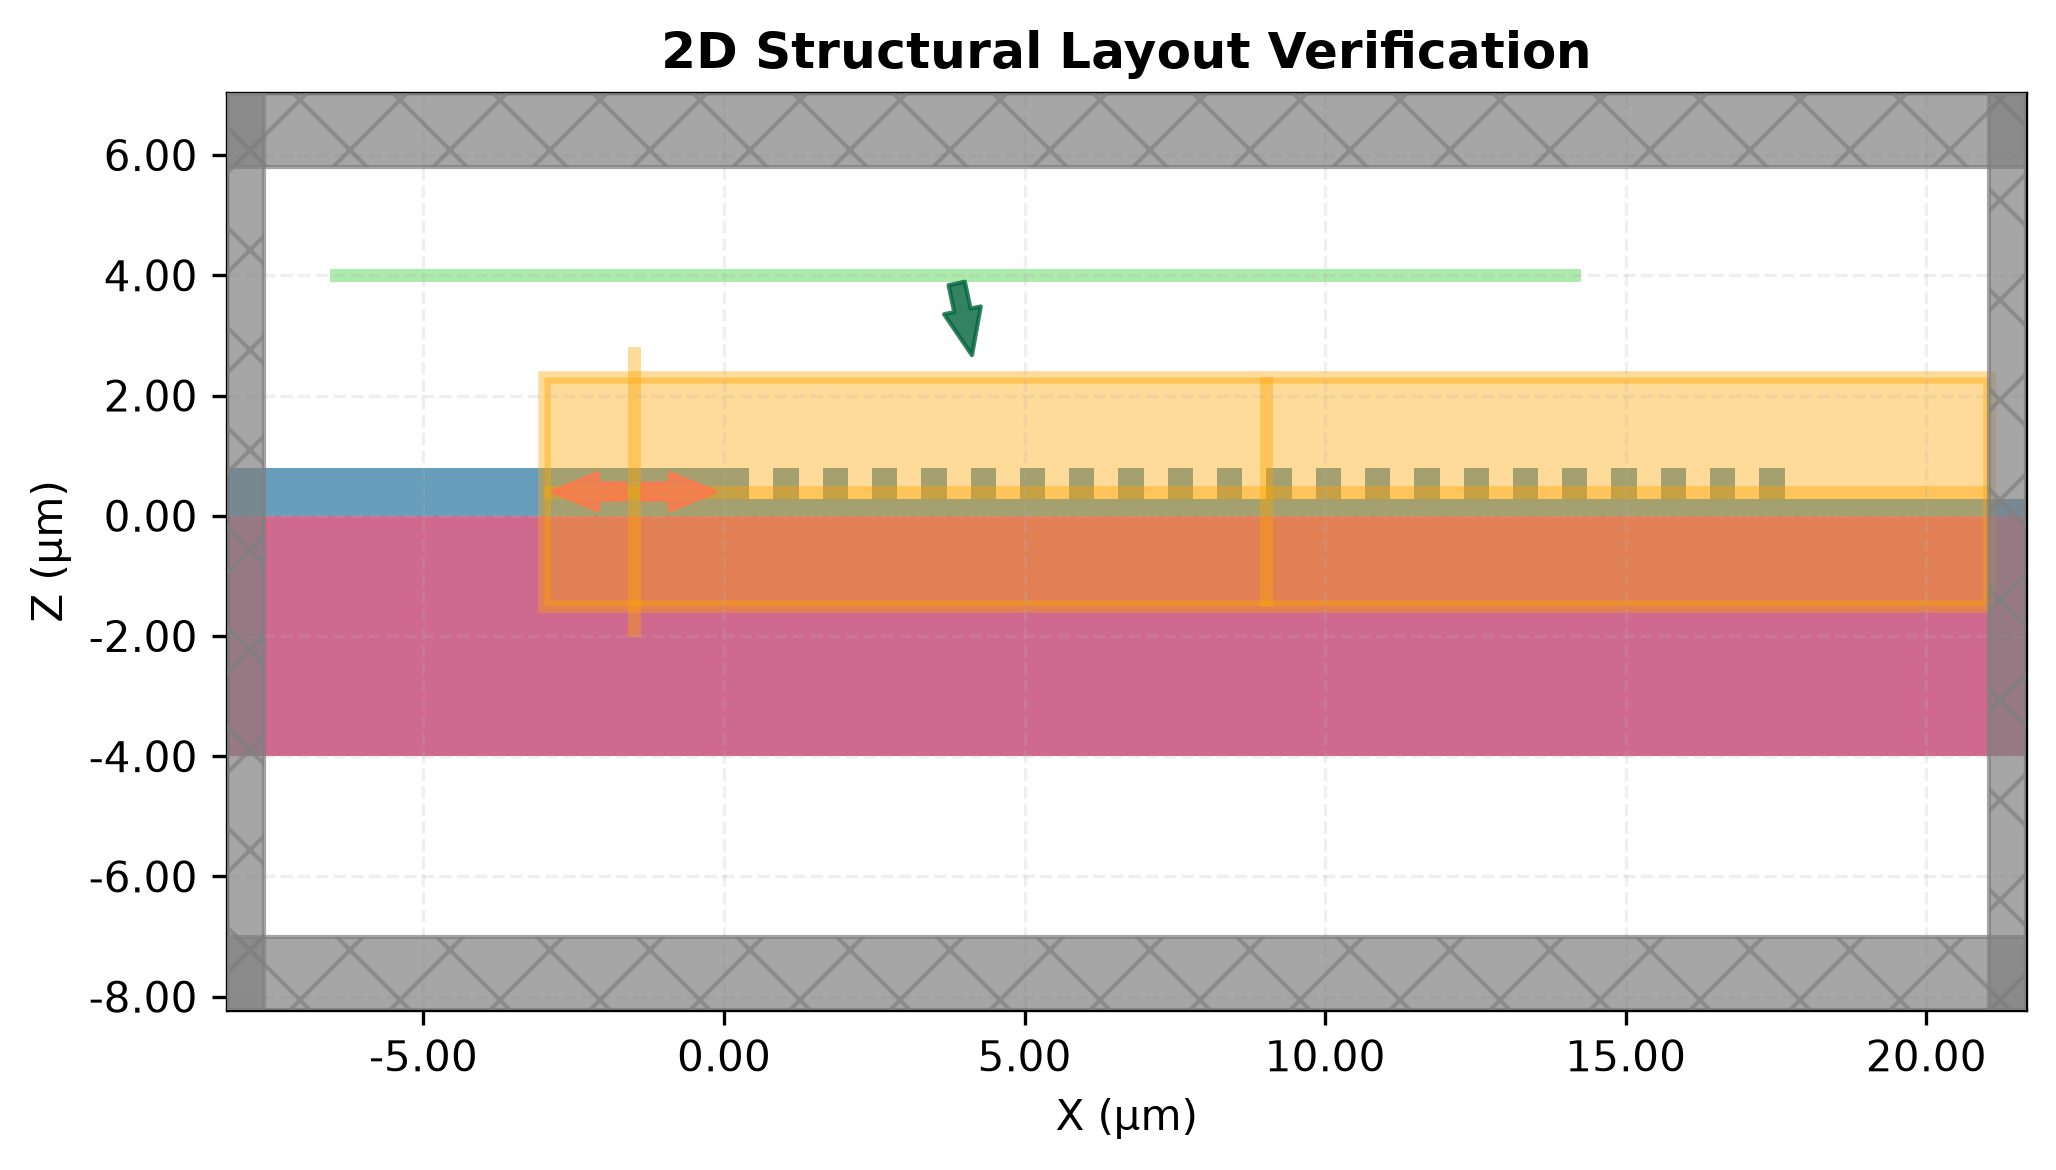

2026-07-23 05:29:25,927 - utilities.sim_plotter - INFO - [Visualizer] 2D geometry layout map saved to: example_results/grating_coupler/example_2d.png


In [2]:
# ---- Defining the Geometry of the Grarting Coupler ---- #

from geometries import grating_coupler
from utilities import sim_plotter
from gratingCoupler import GratingConfig, GratingCoupler

from pathlib import Path
import numpy as np

example_config = GratingConfig(
    wavelength_um=1.550,    # Central wavelength (μm)
    theta_deg=-12.0,        # Fiber incidence angle (degrees off-vertical)
    mfd=10.4,               # Mode Field Diameter (Standard SMF-28)
    source_x=3.8419,        # Fiber beam center X position
    source_gap=2.0,         # Distance between fiber source and top cladding

    # Substrate & Layer Geometry
    core_height=0.800,      # Core thickness (μm)
    cladding_height=2.0,    # Air/Cladding buffer height above core
    box_height=4.0,         # Buried Oxide (BOX) thickness
    substrate_height=8.0,   # Silicon handle thickness

    # Grating Teeth Dimensions
    etch_depth=0.5136,      # Partial etch depth (μm)
    period=0.8201,          # Grating pitch/period (μm)
    ff=0.5136,              # Fill factor (50% tooth, 50% groove)
    n_teeth=22,             # Total number of grating teeth
    w_grating=10.4,        # Transverse width for 3D runs

    # Source & Domain Settings
    pol_angle=np.pi/2,          # 0.0 = TE polarization
    buffer=3.0              # Domain margin buffer
)

example_grating_coupler_3d: GratingCoupler = grating_coupler.get_active_simulation(
    config=example_config,
    core_medium=SiN,
    box_medium=SiO2,
    substrate_medium=None,  
    cladding_medium=Air,    # Air-clad (or pass SiO2 for oxide clad)
    is_3d=True           
)

example_grating_coupler_2d : GratingCoupler = grating_coupler.get_active_simulation(
    config=example_config,
    core_medium=SiN,
    box_medium=SiO2,
    substrate_medium=None,
    cladding_medium=Air,
    is_3d=False
)

sim_plotter.display_3d(
    device = example_grating_coupler_3d,
    output_path = Path("example_results/grating_coupler/example_3d.png"),
    show = True,
    save = True
)

sim_plotter.display_2d(
    device=example_grating_coupler_2d,
    output_path=Path("example_results/grating_coupler/example_2d.png"),
    show = True,
    save = True
)

In [3]:
# ---- Grating Coupler Analytics ---- #

# 1) Coupler efficiency
"""
    The path that is passed to these functions is where the simulation results
    are stored locally after being run on the Tidy3D servers. This ensures that
    if the same configuration is requested more than once, only the first request
    is passed to the Tidy3D servers, and the rest are served from the local data store.

    We have noted that Tidy3D servers do carry out a server-side search to ensure that
    no two simulations are run twice. This layer of local-searching reduces
    latency.

    PROBLEM: As of now the simulation saves are indifferent to the media used to
    build the simulation. This is likely to be corrected with an update to the
    Medium handling architecture.
"""
example_grating_coupler_2d.get_efficiency(Path("example_results/grating_coupler/"))
example_grating_coupler_3d.get_efficiency(Path("example_results/grating_coupler/"))

2026-07-23 05:29:25,936 - root - INFO - [Profiler] Cache miss. Uploading architecture to Tidy3D cloud infrastructure...


05:29:26 IST Loading simulation from local cache. View cached task using web UI 
             at                                                                 
             ]8;id=4549355;https://tidy3d.simulation.cloud/workbench?taskId=fdve-437e0d20-4b99-47da-9d52-9d733f3da120\'https://tidy3d.simulation.cloud/workbench?]8;;\]8;id=4549356;https://tidy3d.simulation.cloud/workbench?taskId=fdve-437e0d20-4b99-47da-9d52-9d733f3da120\taskId]8;;\]8;id=4549355;https://tidy3d.simulation.cloud/workbench?taskId=fdve-437e0d20-4b99-47da-9d52-9d733f3da120\=]8;;\]8;id=4549357;https://tidy3d.simulation.cloud/workbench?taskId=fdve-437e0d20-4b99-47da-9d52-9d733f3da120\fdve]8;;\]8;id=4549355;https://tidy3d.simulation.cloud/workbench?taskId=fdve-437e0d20-4b99-47da-9d52-9d733f3da120\-437e0d20-4b9]8;;\
             ]8;id=4549355;https://tidy3d.simulation.cloud/workbench?taskId=fdve-437e0d20-4b99-47da-9d52-9d733f3da120\9-47da-9d52-9d733f3da120']8;;\.

2026-07-23 05:29:26,227 - root - INFO - [Profiler] Execution complete. Serializing data to example_results/grating_coupler/2D_p_0.8201_dc_0.5136_e_0.5136_n_22_w_10.4000_ch_0.8000_clh_2.0000_bh_4.0000_sh_8.0000_t_-12.0000_mfd_10.4000_sx_3.8419_sg_2.0000_wl_1.5500_pol_1.5708_b_3.0000/raw_simulation_data.hdf5...
2026-07-23 05:29:26,279 - root - INFO - [Analytics] Extracting scattering coefficients from 'mode monitor'...
2026-07-23 05:29:26,285 - root - INFO - [Analytics] Target mode audit completed.
	Coupling Efficiency: 22.27%
	Insertion Loss:      -6.52 dB
2026-07-23 05:29:26,286 - root - INFO - [Profiler] Cache miss. Uploading architecture to Tidy3D cloud infrastructure...


05:29:36 IST Created task 'gc_sim_1.55um' with resource_id                      
             'fdve-3fd27778-4621-42bf-8ae1-213915b96cd0' and task_type 'FDTD'.

             View task using web UI at                                          
             ]8;id=4549361;https://tidy3d.simulation.cloud/workbench?taskId=fdve-3fd27778-4621-42bf-8ae1-213915b96cd0\'https://tidy3d.simulation.cloud/workbench?]8;;\]8;id=4549362;https://tidy3d.simulation.cloud/workbench?taskId=fdve-3fd27778-4621-42bf-8ae1-213915b96cd0\taskId]8;;\]8;id=4549361;https://tidy3d.simulation.cloud/workbench?taskId=fdve-3fd27778-4621-42bf-8ae1-213915b96cd0\=]8;;\]8;id=4549363;https://tidy3d.simulation.cloud/workbench?taskId=fdve-3fd27778-4621-42bf-8ae1-213915b96cd0\fdve]8;;\]8;id=4549361;https://tidy3d.simulation.cloud/workbench?taskId=fdve-3fd27778-4621-42bf-8ae1-213915b96cd0\-3fd27778-462]8;;\
             ]8;id=4549361;https://tidy3d.simulation.cloud/workbench?taskId=fdve-3fd27778-4621-42bf-8ae1-213915b96cd0\1-42bf-8ae1-213915b96cd0']8;;\.

             Task folder: ]8;id=4549366;https://tidy3d.simulation.cloud/folders/folder-31ab8ed9-04f8-4aab-bdd9-855af6d8b115\'default']8;;\.

... (10 outputs left out)

05:30:54 IST View simulation result at                                          
             ]8;id=4549369;https://tidy3d.simulation.cloud/workbench?taskId=fdve-3fd27778-4621-42bf-8ae1-213915b96cd0\'https://tidy3d.simulation.cloud/workbench?]8;;\]8;id=4549370;https://tidy3d.simulation.cloud/workbench?taskId=fdve-3fd27778-4621-42bf-8ae1-213915b96cd0\taskId]8;;\]8;id=4549369;https://tidy3d.simulation.cloud/workbench?taskId=fdve-3fd27778-4621-42bf-8ae1-213915b96cd0\=]8;;\]8;id=4549371;https://tidy3d.simulation.cloud/workbench?taskId=fdve-3fd27778-4621-42bf-8ae1-213915b96cd0\fdve]8;;\]8;id=4549369;https://tidy3d.simulation.cloud/workbench?taskId=fdve-3fd27778-4621-42bf-8ae1-213915b96cd0\-3fd27778-462]8;;\
             ]8;id=4549369;https://tidy3d.simulation.cloud/workbench?taskId=fdve-3fd27778-4621-42bf-8ae1-213915b96cd0\1-42bf-8ae1-213915b96cd0']8;;\.

05:36:38 IST Loading results from simulation_data.hdf5

2026-07-23 05:36:43,906 - root - INFO - [Profiler] Execution complete. Serializing data to example_results/grating_coupler/3D_p_0.8201_dc_0.5136_e_0.5136_n_22_w_10.4000_ch_0.8000_clh_2.0000_bh_4.0000_sh_8.0000_t_-12.0000_mfd_10.4000_sx_3.8419_sg_2.0000_wl_1.5500_pol_1.5708_b_3.0000/raw_simulation_data.hdf5...
2026-07-23 05:36:44,064 - root - INFO - [Analytics] Extracting scattering coefficients from 'mode monitor'...
2026-07-23 05:36:44,067 - root - INFO - [Analytics] Target mode audit completed.
	Coupling Efficiency: 18.51%
	Insertion Loss:      -7.33 dB


0.1851130485415452

2026-07-23 05:36:44,076 - root - INFO - [Profiler] Cache hit. Loading existing simulation data from example_results/grating_coupler/2D_p_0.8201_dc_0.5136_e_0.5136_n_22_w_10.4000_ch_0.8000_clh_2.0000_bh_4.0000_sh_8.0000_t_-12.0000_mfd_10.4000_sx_3.8419_sg_2.0000_wl_1.5500_pol_1.5708_b_3.0000/raw_simulation_data.hdf5...
[Analytics] Processing spatial field distributions (2D mode)...
2026-07-23 05:36:44,153 - root - INFO - [Analytics] Skipping 3D-only slice 'field_x_plane' for 2D simulation.
2026-07-23 05:36:44,739 - root - INFO - [Analytics] Exported field profile slice: spatial_field_field_y_plane.png


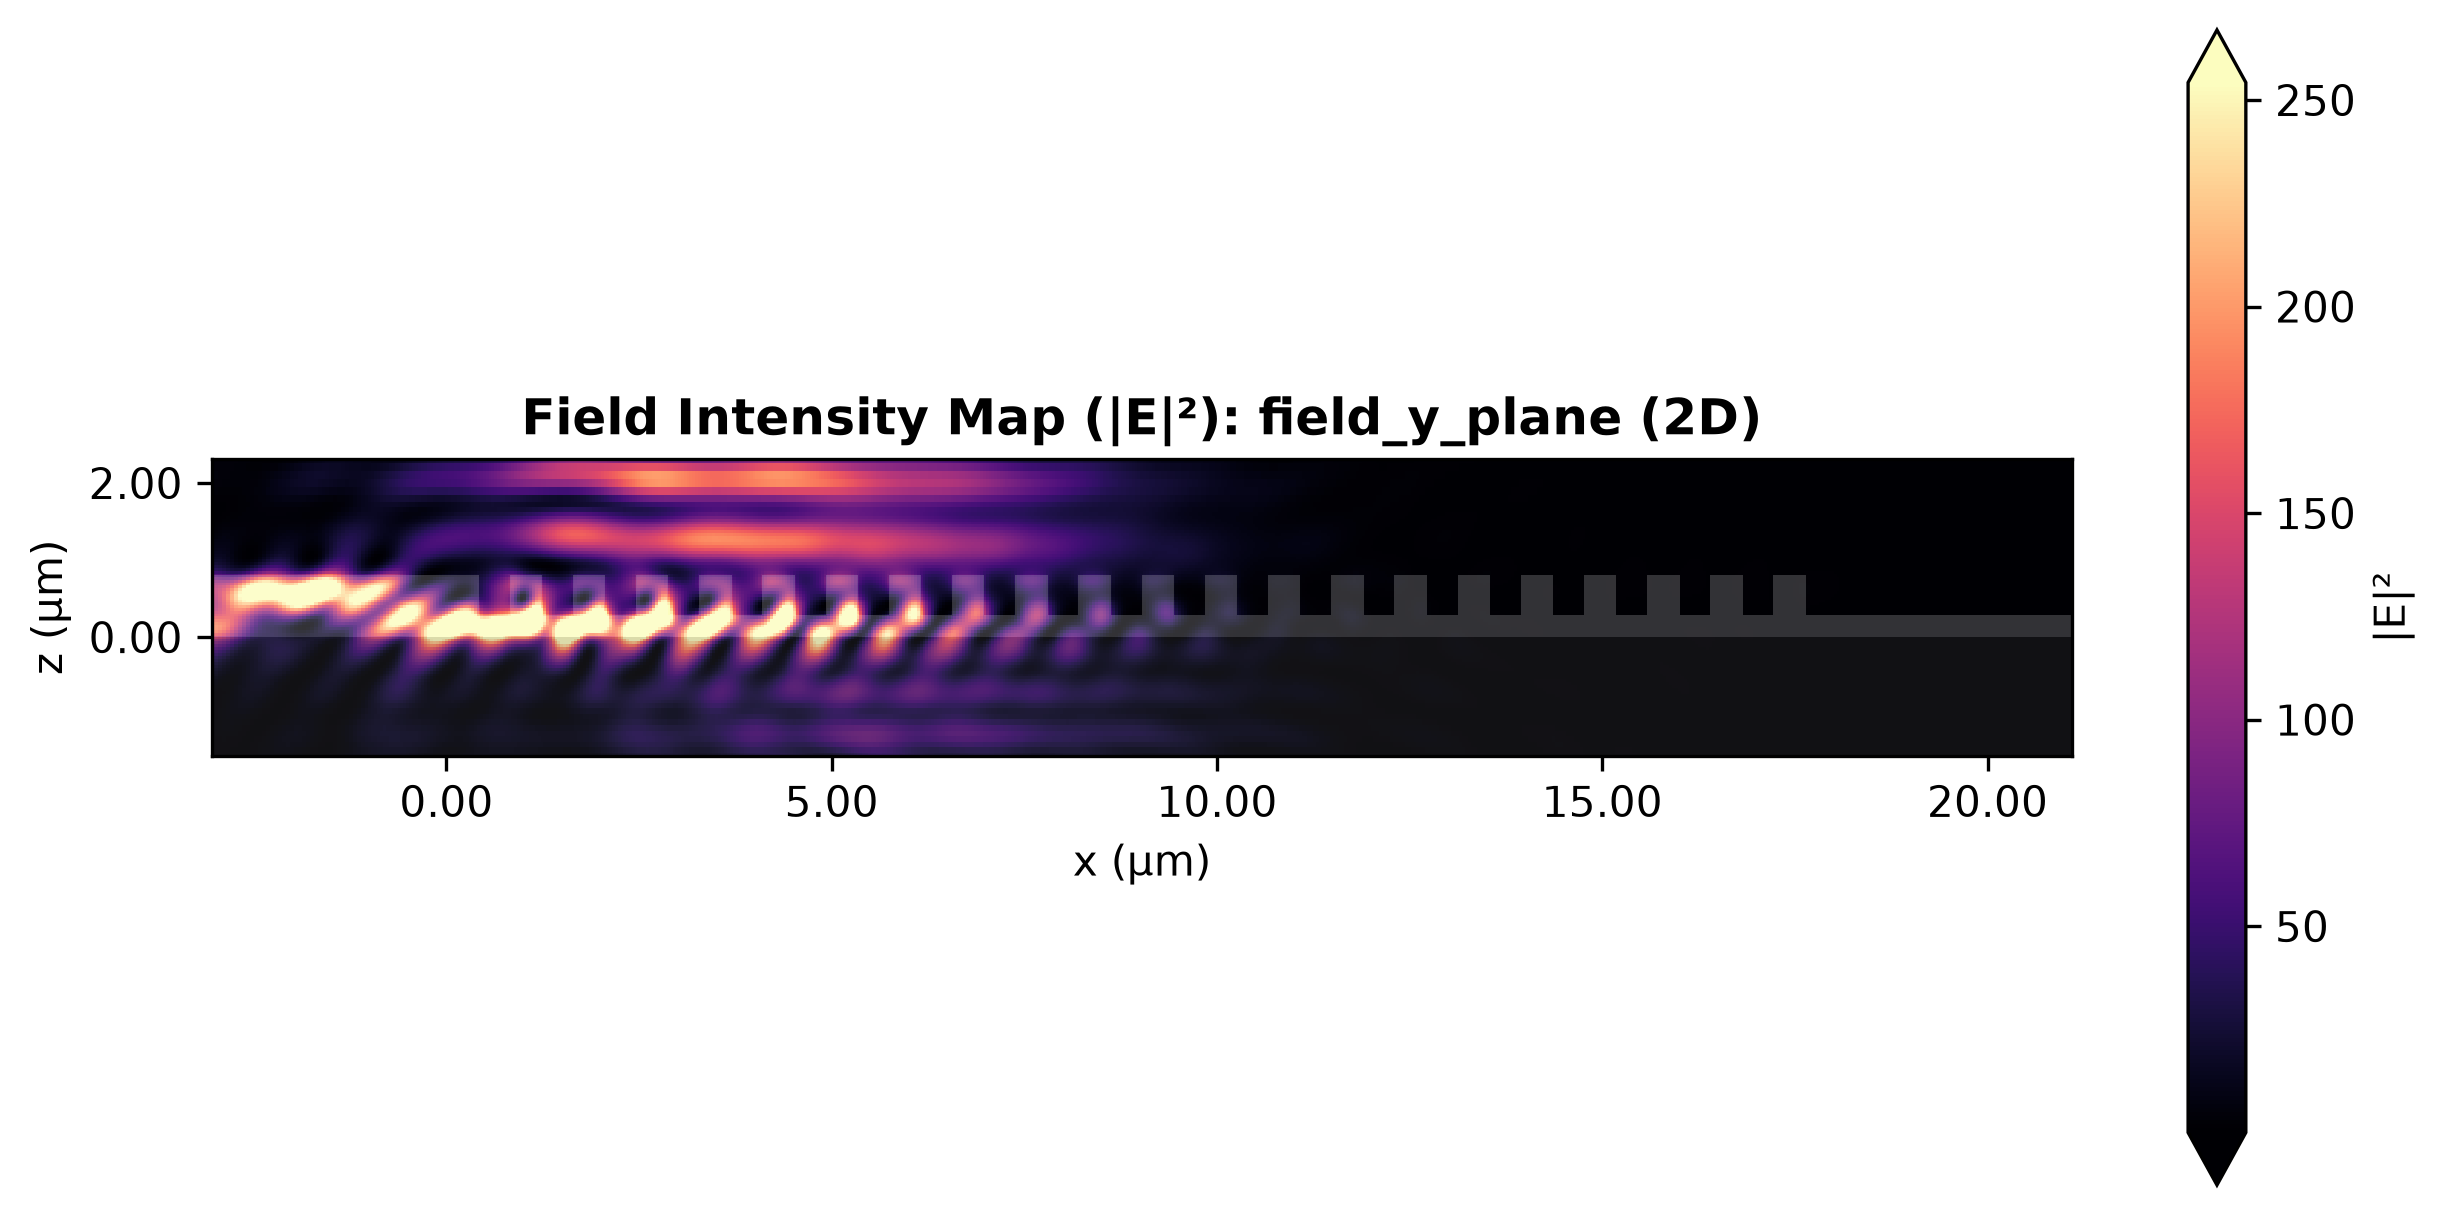

2026-07-23 05:36:44,865 - root - INFO - [Analytics] Skipping 3D-only slice 'field_z_plane' for 2D simulation.
2026-07-23 05:36:44,866 - root - INFO - [Profiler] Cache hit. Loading existing simulation data from example_results/grating_coupler/3D_p_0.8201_dc_0.5136_e_0.5136_n_22_w_10.4000_ch_0.8000_clh_2.0000_bh_4.0000_sh_8.0000_t_-12.0000_mfd_10.4000_sx_3.8419_sg_2.0000_wl_1.5500_pol_1.5708_b_3.0000/raw_simulation_data.hdf5...
[Analytics] Processing spatial field distributions (3D mode)...
2026-07-23 05:36:45,419 - root - INFO - [Analytics] Exported field profile slice: spatial_field_field_x_plane.png


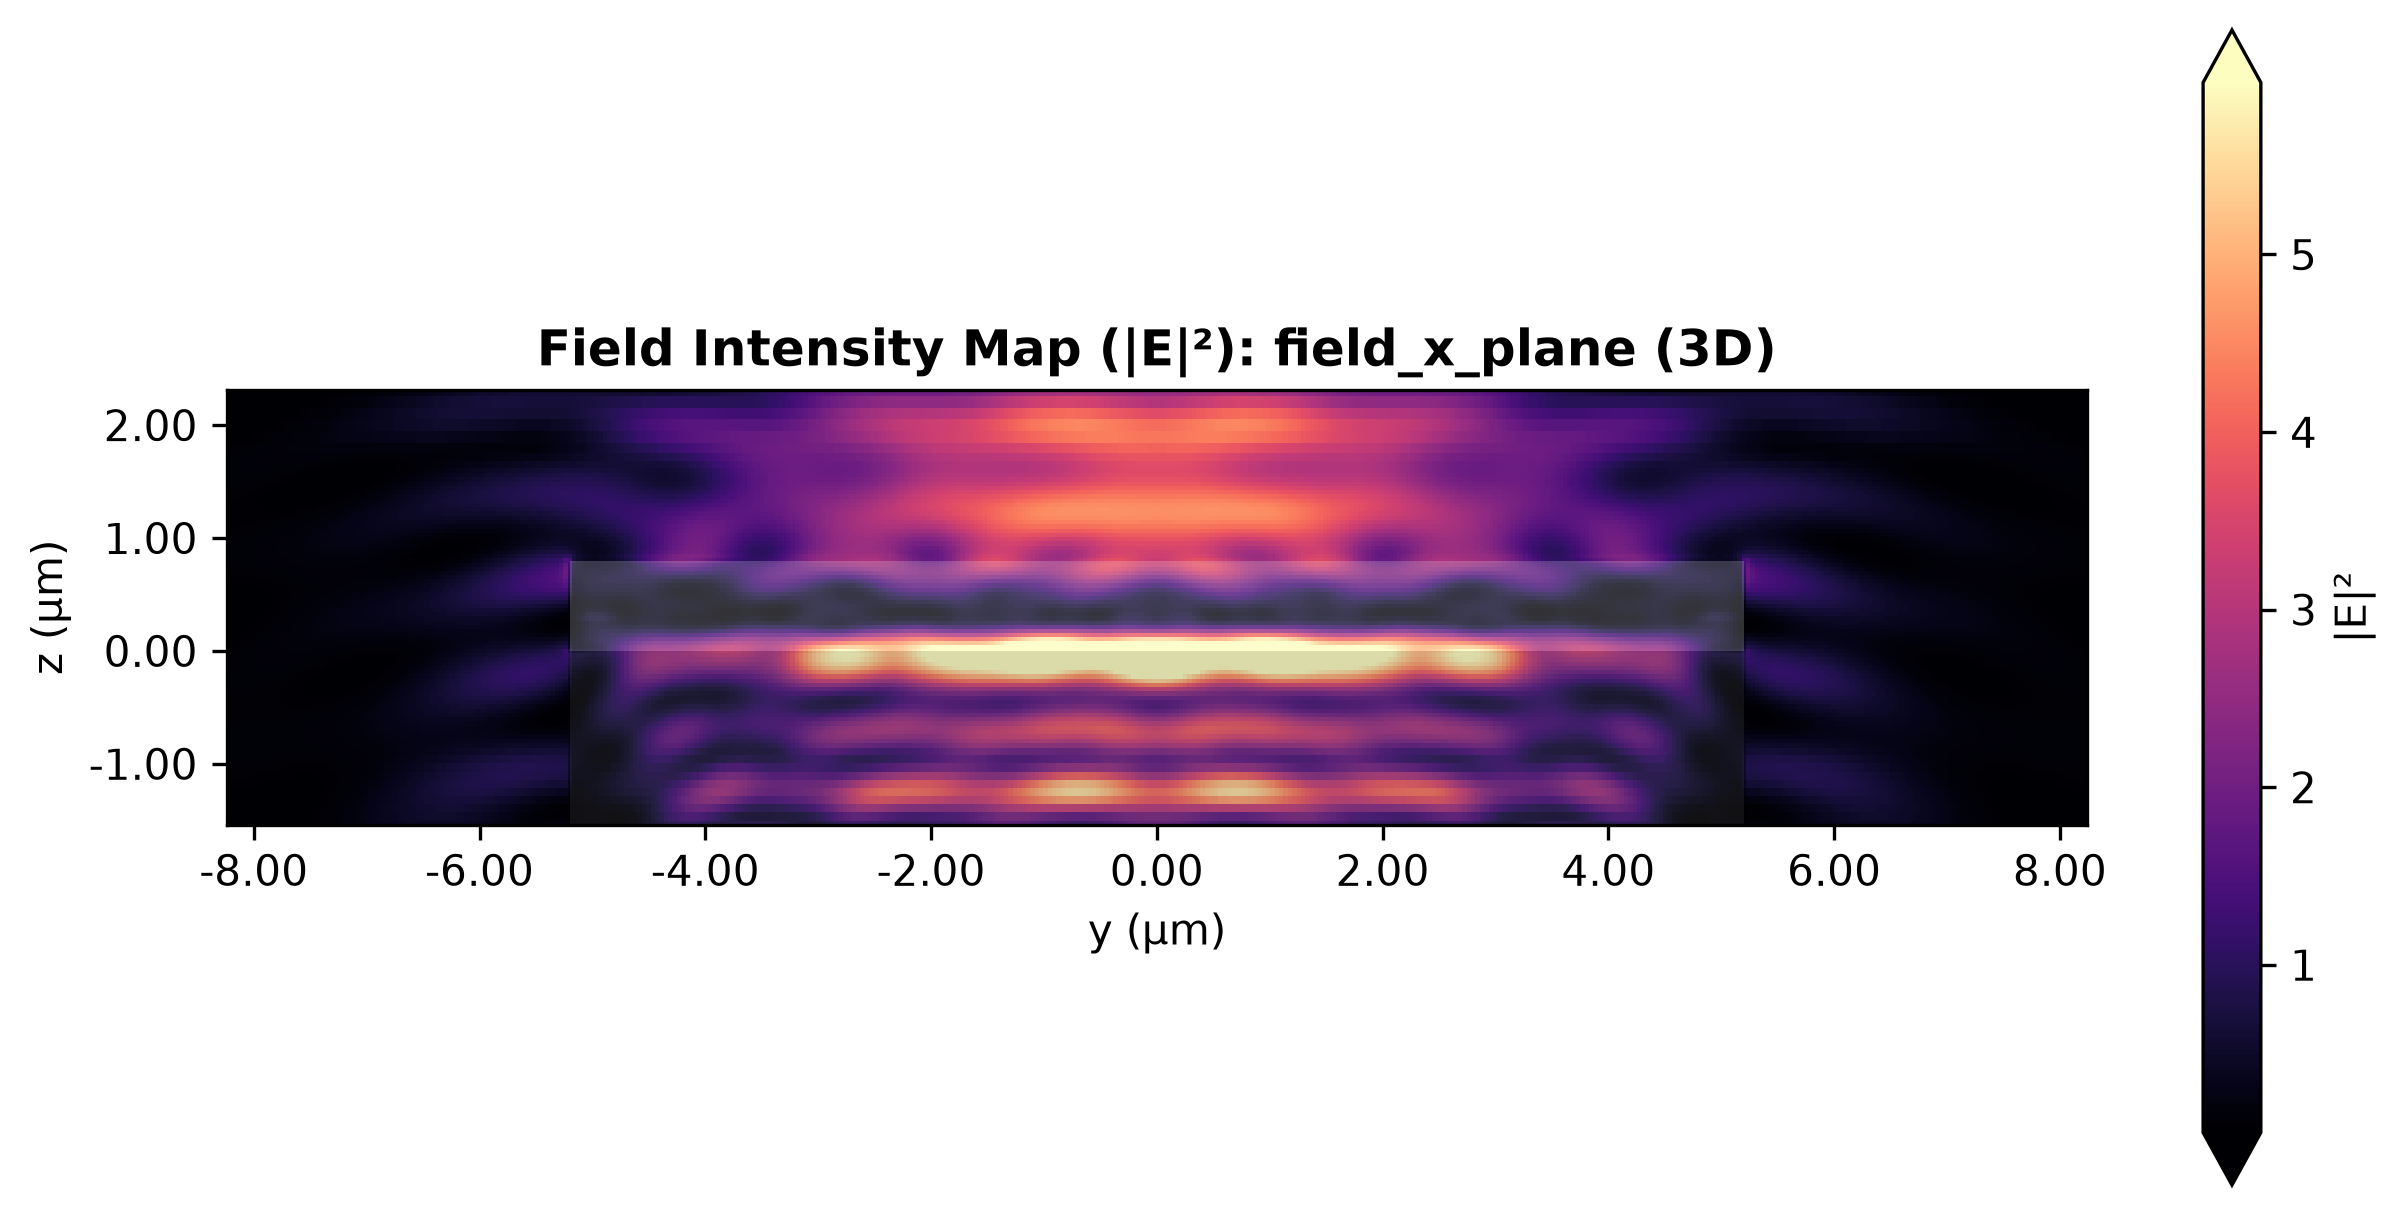

2026-07-23 05:36:46,148 - root - INFO - [Analytics] Exported field profile slice: spatial_field_field_y_plane.png


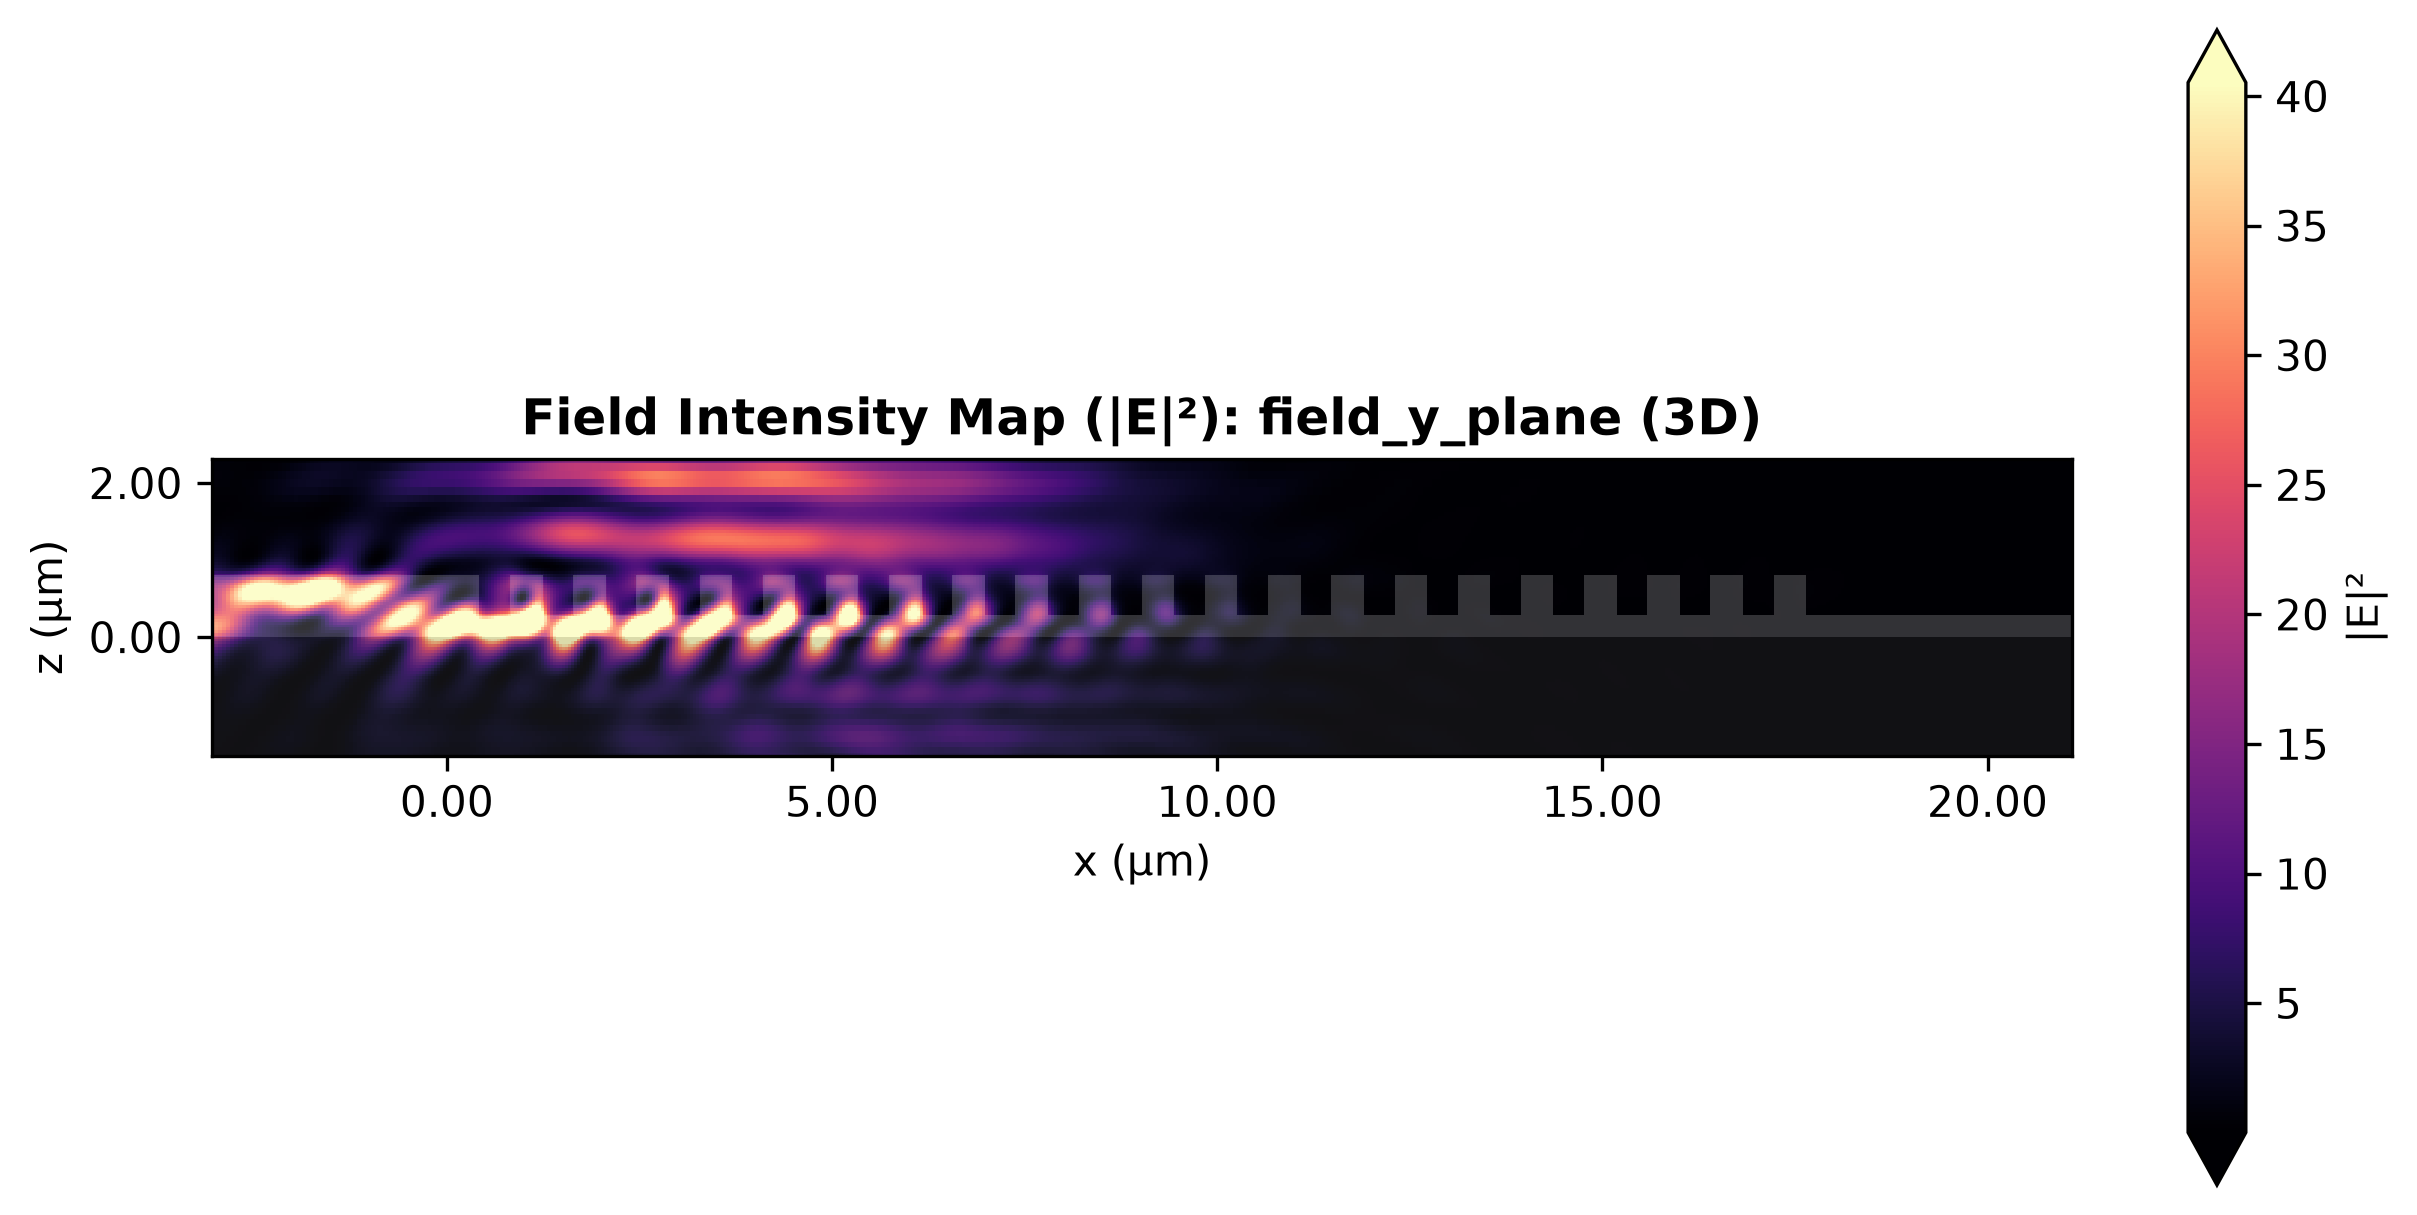

2026-07-23 05:36:47,190 - root - INFO - [Analytics] Exported field profile slice: spatial_field_field_z_plane.png


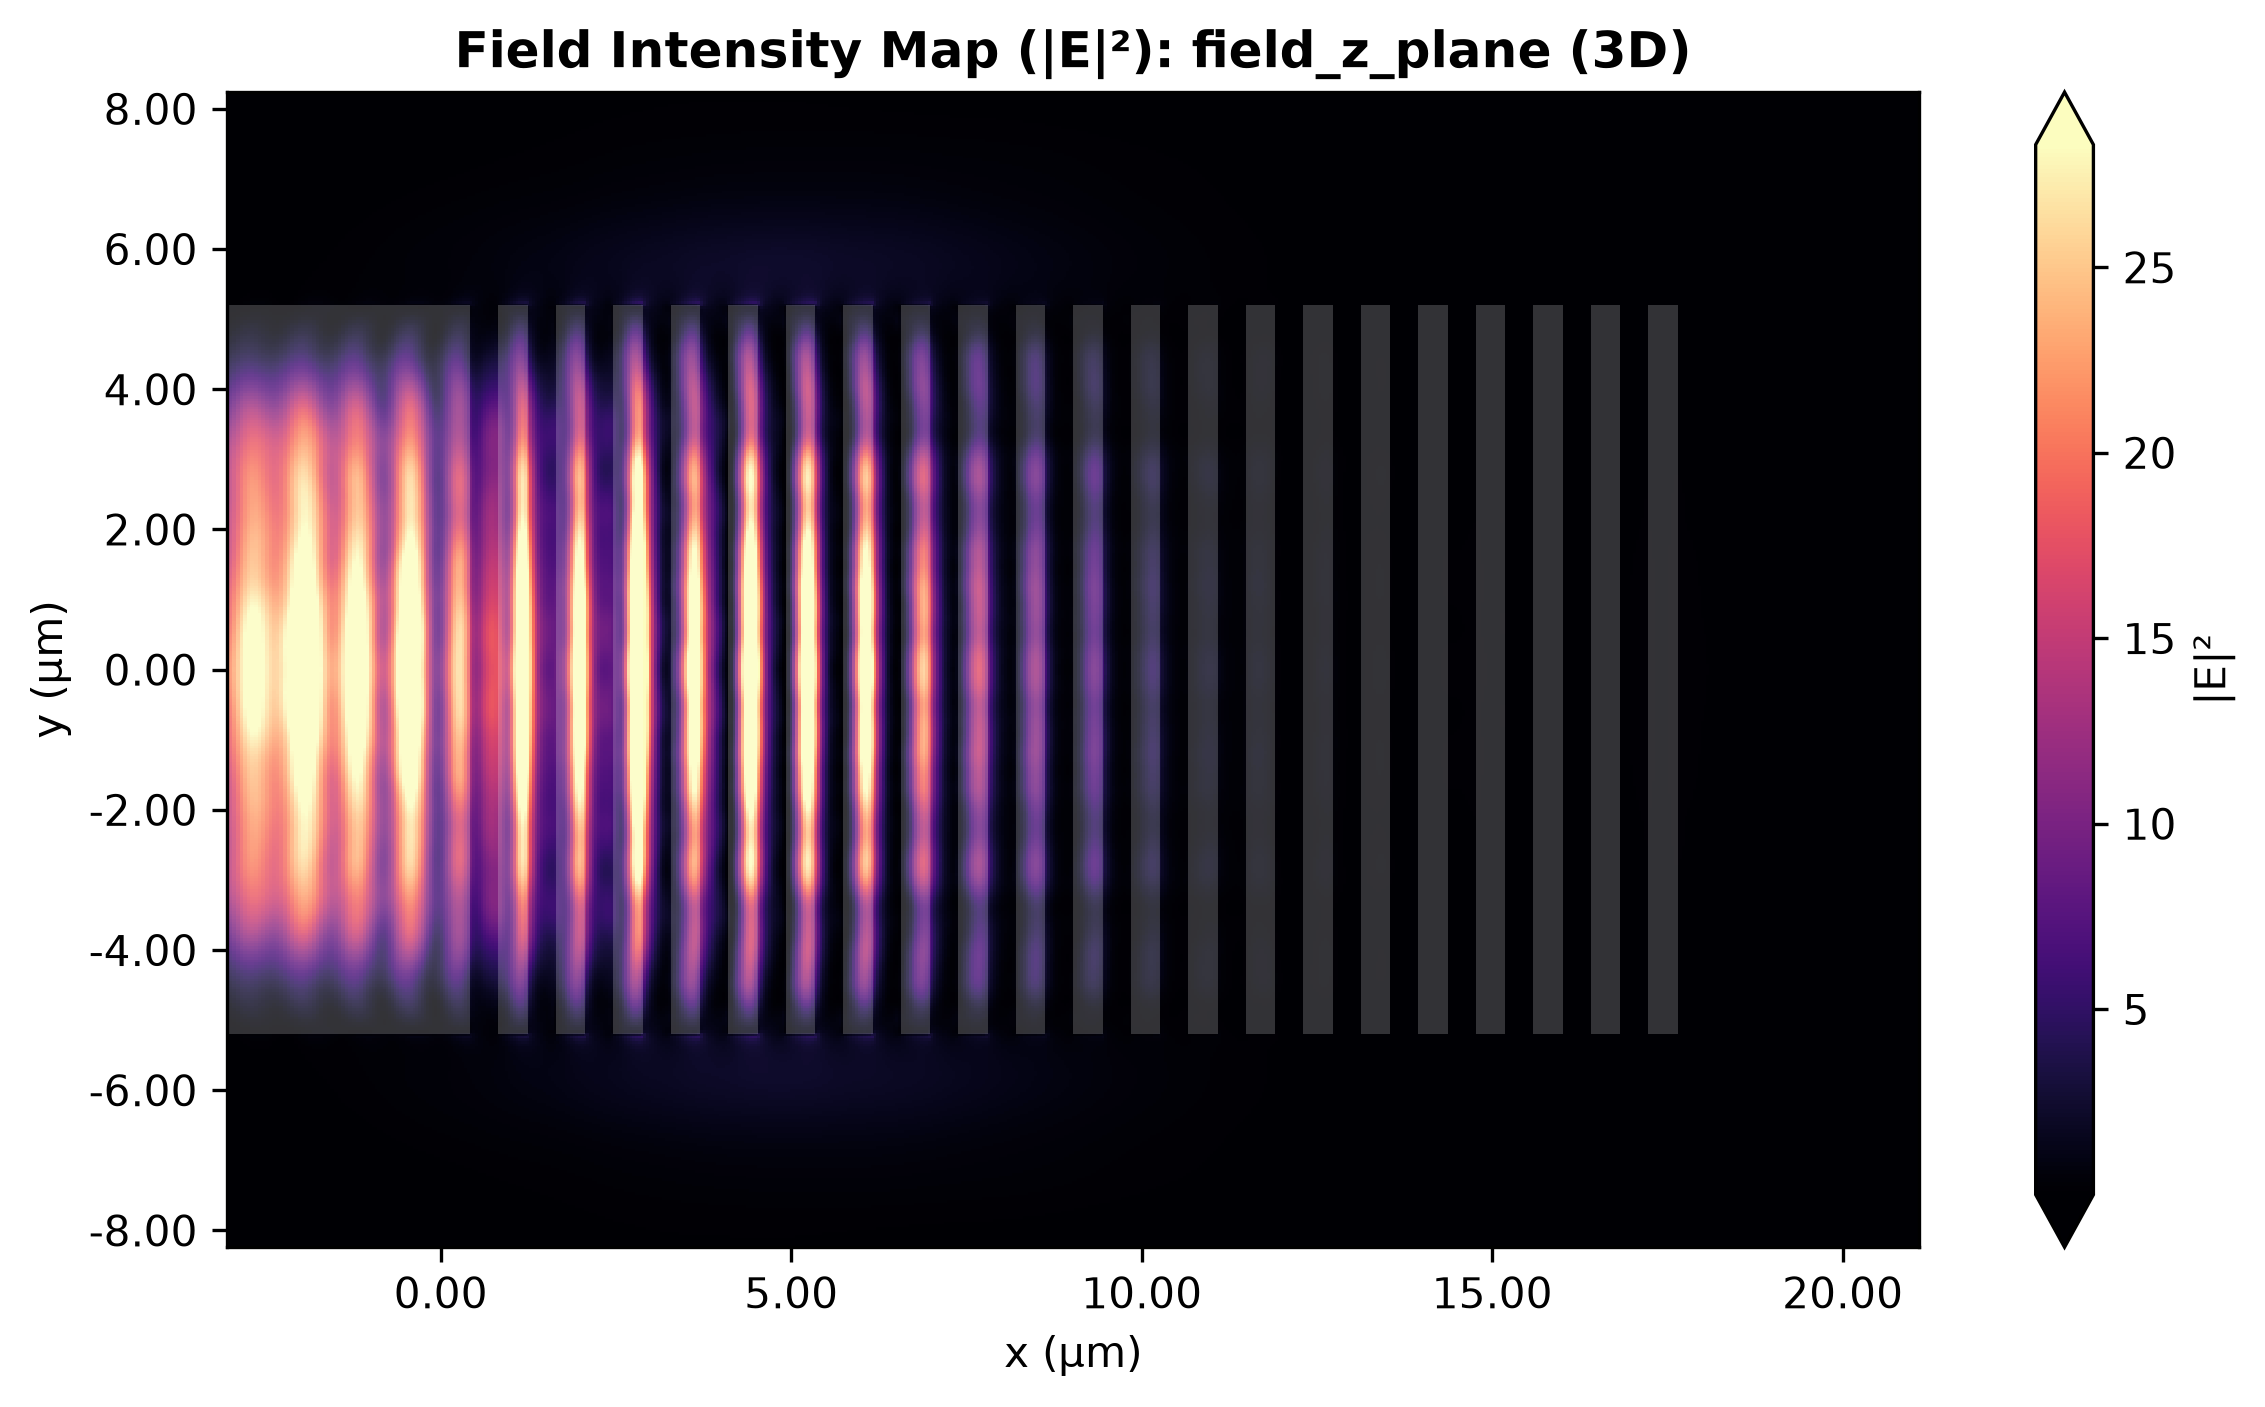

In [4]:
# 2) Visualize fields within the coupler
example_grating_coupler_2d.get_fields(Path("example_results/grating_coupler/"))
example_grating_coupler_3d.get_fields(Path("example_results/grating_coupler/"))